# 3.0 — Théorie de l'information : entropie, KL, cross-entropy

**Navigation** : [<< 2.3-Régression linéaire et logistique](../02-ML-Cours/2.3-Regression-lineaire-logistique.ipynb) · [2.8-Théorie-PAC](../02-ML-Cours/2.8-Theorie-PAC.ipynb) · [2.9-Grokking](../02-ML-Cours/2.9-Grokking-Generalisation.ipynb) · [Feuille de route de la série](README.md) · [Version C#](3.0-Theorie-Information-CSharp.ipynb) · [3.1 — La rétropropagation >>](3.1-Retropropagation.ipynb)

Le notebook [2.3](../02-ML-Cours/2.3-Regression-lineaire-logistique.ipynb) vous a montré que la régression logistique est ajustée par le **maximum de vraisemblance**. Ce notebook ouvre la boîte de ce qu'on optimise vraiment : la **cross-entropy**. C'est la première pierre de la série 03 — avant d'écrire la rétropropagation (3.1) et les optimiseurs (3.2), il faut savoir *ce que* la loss mesure.

Toute la théorie de l'information tient en trois quantités. On les construit ici **from scratch**, on les **vérifie** numériquement sur un vrai texte français, puis on les relie aux losses que le reste de la série consomme : le `LogSoftmax` d'une tête de classification, le penalty KL du DPO ([PT_03](../../../GenAI/PostTraining/PT_03_dpo_direct_preference.ipynb)) et le ratio KL de la régularisation PPO/GRPO ([PT_04](../../../GenAI/PostTraining/PT_04_grpo_deepseek_r1.ipynb)).

**Objectifs** : calculer H, CE et KL, comparer deux objectifs de classification et mesurer l’effet de la température.

**Durée conseillée** : 45 minutes.

**Kernel** : Python 3 · **Bibliothèques** : NumPy, matplotlib, scikit-learn · **CPU** : oui (~1 min) · **Prérequis** : 2.3 (régression logistique), 2.8 (bornes), un peu de probabilités


***

## 1. L'entropie : la surprise moyenne d'une source

Un **message** est un tirage de caractères selon une distribution $p$. L'information apportée par un symbole $x$ est sa **surprise** : $-\log_2 p(x)$, en bits. Un symbole fréquent ($p$ grand) surprend peu, un symbole rare ($p$ petit) surprend beaucoup. L'**entropie** $H(p) = -\sum_x p(x) \log_2 p(x)$ est l'information moyenne par tirage — le taux idéal en bits par symbole ; un code préfixe symbole par symbole impose des longueurs entières, tandis que le codage par blocs peut approcher ce taux.

Deux bornes la cadrent : $H(p) \ge 0$ (la surprise n'est pas négative) et $H(p) \le \log_2 K$ où $K$ est la taille de l'alphabet (l'entropie est maximale quand la distribution est **uniforme**). Le rapport $H / \log_2 K$ mesure l'**efficacité** de la source ; son complément $1 - H / \log_2 K$ est la **redondance**. Plus le rapport est bas, plus la source est compressible.

On mesure tout ça sur un vrai texte français (une fable de La Fontaine, domaine public), au niveau des caractères.


In [1]:
import sys
import numpy as np
import sklearn
print(f"Python {sys.version.split()[0]} ; NumPy {np.__version__} ; sklearn {sklearn.__version__}")

TEXTE = """Maître Corbeau, sur un arbre perché, tenait en son bec un fromage.
Maître Renard, par l'odeur alléché, lui tint à peu près ce langage :
« Bonjour, Monsieur du Corbeau. Que vous êtes joli ! que vous me semblez beau !
Sans mentir, si votre ramage se rapporte à votre plumage, vous êtes le Phénix
des hôtes de ces bois. » À ces mots le Corbeau ne se sent pas de joie ; et pour
montrer sa belle voix, il ouvre un large bec, laisse tomber sa proie. Le Renard
s'en saisit, et dit : « Mon bon Monsieur, apprenez que tout flatteur vit aux
dépens de celui qui l'écoute : cette leçon vaut bien un fromage, sans doute. »
Le Corbeau, honteux et confus, jura, mais un peu tard, qu'on ne l'y prendrait plus.

La Cigale, ayant chanté tout l'été, se trouva fort dépourvue quand la bise fut
venue : pas un seul petit morceau de mouche ou de vermisseau. Elle alla crier
famine chez la Fourmi sa voisine, la priant de lui prêter quelque grain pour
subsister jusqu'à la saison nouvelle. « Je vous paierai, lui dit-elle, avant
l'août, foi d'animal, intérêt et principal. » La Fourmi n'est pas prêteuse :
c'est là son moindre défaut. « Que faisiez-vous au temps chaud ? dit-elle à
cette emprunteuse. — Nuit et jour à tout venant je chantais, ne vous déplaise.
— Vous chantiez ? j'en suis fort aise. Eh bien ! dansez maintenant. »"""

def compter_caracteres(texte):
    """Occurrences de chaque caractere."""
    occ = {}
    for c in texte:
        occ[c] = occ.get(c, 0) + 1
    return occ

def entropie(occ):
    """H = -sum p log2 p, en bits. p = frequence des caracteres."""
    n = sum(occ.values())
    if not occ or n <= 0 or any(not np.isfinite(k) or k < 0 for k in occ.values()):
        raise ValueError("comptages non négatifs de somme positive requis")
    h = 0.0
    for c, k in occ.items():
        p = k / n
        if p > 0:
            h -= p * np.log2(p)
    return h

occ = compter_caracteres(TEXTE)
n_car = sum(occ.values())
n_dist = len(occ)
H = entropie(occ)
H_max = np.log2(n_dist)

alphabet = sorted(occ.keys())                    # ordre canonique des symboles
p = np.array([occ[c] for c in alphabet], dtype=float) / n_car   # distribution empirique

print(f"caractères : {n_car}  |  symboles distincts : {n_dist}")
print(f"H(texte) = {H:.4f} bits/caractère")
print(f"H_max (uniforme sur {n_dist} symboles) = {H_max:.4f} bits")
print(f"redondance = {1 - H / H_max:.1%}")
print(f"bornes 0 <= H <= log2(K) : {0.0 <= H <= H_max + 1e-9}  (K={n_dist})")


Python 3.13.16 ; NumPy 2.4.4 ; sklearn 1.9.1
caractères : 1307  |  symboles distincts : 59
H(texte) = 4.5334 bits/caractère
H_max (uniforme sur 59 symboles) = 5.8826 bits
redondance = 22.9%
bornes 0 <= H <= log2(K) : True  (K=59)


**Lecture.** Sur ces 1 307 caractères et 59 symboles, l'entropie empirique vaut 4,5334 bits/caractère contre 5,8826 bits au maximum uniforme, soit 22,9 % de redondance. Ce seul texte ne définit pas une loi universelle du français ; cette statistique unigramme ne mesure pas les dépendances entre caractères.

## Exercice 1 — Entropie du second texte

Implémentez l'entropie en bits par caractère et comparez le texte français au texte anglais fourni, inchangé. Expliquez pourquoi la redondance normalisée d'un pangramme court est biaisée. Refusez un texte vide. Le contrôle compare plusieurs textes non triviaux.

In [2]:
# Exercice 1 : entropie d'un second texte, en bits par caractère.
TEXTE_2 = """The quick brown fox jumps over the lazy dog. Pack my box with five dozen liquor jugs."""
def entropie_texte(texte):
    # TODO étudiant : compter les caractères et calculer leur entropie.
    return None

def verifier_entropie(f):
    import math
    for texte in ["aaaa", "abab", "abbc", TEXTE_2]:
        compte = {c: texte.count(c) for c in set(texte)}
        attendu = -sum((n / len(texte)) * math.log2(n / len(texte)) for n in compte.values())
        valeur = f(texte)
        if valeur is None:
            return False
        if not math.isfinite(valeur) or not math.isclose(valeur, attendu, abs_tol=1e-10):
            raise AssertionError("entropie incorrecte")
    try: f("")
    except ValueError: pass
    else: raise AssertionError("texte vide accepté")
    return True
print("Exercice 1 :", "validé" if verifier_entropie(entropie_texte) else "à compléter")

Exercice 1 : à compléter


***

## 2. Cross-entropy et divergence de KL : le coût de croire un modèle

L'entropie $H(p)$ suppose que *je connais* la vraie distribution $p$. En apprentissage, on ne la connaît pas : on a un **modèle** qui produit $q$, et on veut mesurer combien il coûte d'utiliser $q$ alors que la vérité est $p$. La **cross-entropy** $H(p, q) = -\sum_x p(x) \log_2 q(x)$ est ce coût : le coût idéal d’un code ajusté à $q$, évalué sur des tirages de $p$.

La **divergence de Kullback–Leibler** $D_{KL}(p \| q) = \sum_x p(x) \log_2 \frac{p(x)}{q(x)}$ isole le **surcoût** de $q$ par rapport à $p$ : c'est la « distance » que $q$ ajoute, en bits, au prix optimal. Les deux sont liées par l'identité fondamentale $H(p, q) = H(p) + D_{KL}(p \| q)$.

Deux propriétés font de la KL un outil de théorie de l'apprentissage : la **positivité** $D_{KL}(p \| q) \ge 0$ (inégalité de Gibbs, égalité ssi $p = q$), et son **asymétrie** — $D_{KL}(p \| q) \neq D_{KL}(q \| p)$ — ce qui en fait une *divergence*, pas une métrique. On vérifie les deux numériquement, avec le piège classique du $\log 0$.


In [3]:
# Cross-entropy et divergence de KL : definitions from scratch + verification numerique.
import numpy as np

def normaliser(v):
    v = np.asarray(v, dtype=float)
    if v.ndim != 1 or not len(v) or not np.all(np.isfinite(v)) or np.any(v < 0) or v.max() <= 0:
        raise ValueError("vecteur fini, non négatif et de somme positive requis")
    echelle = v.max()
    scaled = v / echelle
    return scaled / scaled.sum()

def distributions(p, q):
    p, q = np.asarray(p, dtype=float), np.asarray(q, dtype=float)
    for v in (p, q):
        if v.ndim != 1 or not len(v) or not np.all(np.isfinite(v)) or np.any(v < 0) or not np.isclose(v.sum(), 1, rtol=0, atol=1e-12):
            raise ValueError("distribution finie, non négative et de somme 1 requise")
    if p.shape != q.shape:
        raise ValueError("dimensions différentes")
    return p, q

def cross_entropy(p, q):
    """Cross-entropy exacte en bits ; zéro de q sur le support de p donne +inf."""
    p, q = distributions(p, q)
    mask = p > 0
    if np.any(q[mask] == 0):
        return float("inf")
    return float(-np.sum(p[mask] * np.log2(q[mask])))

def entropie_p(p):
    return cross_entropy(p, p)

def kl(p, q):
    p, q = distributions(p, q)
    mask = p > 0
    if np.any(q[mask] == 0):
        return float("inf")
    return float(np.sum(p[mask] * (np.log2(p[mask]) - np.log2(q[mask]))))

def ce_sans_lissage(p, q):
    return cross_entropy(p, q)

# Un "modele" q : perturbation douce de la distribution empirique p (aplatit + bruit).
rng = np.random.default_rng(7)
q = normaliser(p ** 1.3 + 0.02 * rng.random(len(p)))

H_p = entropie_p(p)
H_pq = cross_entropy(p, q)
K = kl(p, q)

print("=== Verifications numeriques ===  ")
print(f"H(p)      = {H_p:.6f} bits")
print(f"H(p, q)   = {H_pq:.6f} bits")
print(f"D(p||q)   = {K:.6f} bits")
print(f"identite H(p,q) = H(p) + D(p||q)  -> ecart : {abs(H_pq - (H_p + K)):.2e}")
print(f"KL(p||p) = {kl(p, p):.2e}  (doit etre 0)")

# Positivite de la KL sur un balayage de perturbations.
k_min = float("inf")
for a in np.linspace(0.5, 2.5, 21):
    for s in range(4):
        qq = normaliser(p ** a + 0.01 * s)
        k_min = min(k_min, kl(p, qq))
print(f"KL minimale sur le balayage = {k_min:.2e}  (>= 0, Gibbs)")

# Asymetrie D(p||q) vs D(q||p).
print(f"asymetrie : D(p||q) = {K:.4f}  vs  D(q||p) = {kl(q, p):.4f}  -> differe (divergence, pas metrique)")

# Le piege du log(0) : si q met une masse nulle la ou p > 0, la cross-entropy saute a +inf.
idx = int(np.argmax(p))            # un symbole frequent, p[idx] > 0
q_zero = q.copy()
q_zero[idx] = 0.0
q_zero = normaliser(q_zero)        # renormalise (masse nulle au symbole idx)
with np.errstate(divide="ignore"):
    ce_raw = ce_sans_lissage(p, q_zero)
print("\nSans lissage, q avec un 0 sur un symbole de p -> cross-entropy =", ce_raw)
print("Avec lissage additif normalisé alpha=1e-12 -> cross-entropy =", cross_entropy(p, normaliser(q_zero + 1e-12)))

# Cas limites et contrôle indépendant.
assert entropie_p([1, 0]) == 0 and cross_entropy([1, 0], [1, 0]) == 0
assert np.isinf(cross_entropy([1, 0], [0, 1]))
for bad in ([], [0, 0], [np.nan, 1], [np.inf, 0], [-1, 2], [.2, .2]):
    try:
        entropie_p(bad)
    except ValueError:
        pass
    else:
        raise AssertionError("distribution invalide acceptée")
print("Contrats zéros et distributions invalides : OK")

assert np.allclose(normaliser([1e308, 1e308]), [.5, .5])
assert abs(kl([1, 0], [1e-320, 1.]) + np.log2(1e-320)) < 1e-10
print("Poids extrêmes et KL subnormale : OK")


=== Verifications numeriques ===  
H(p)      = 4.533427 bits
H(p, q)   = 5.031441 bits
D(p||q)   = 0.498014 bits
identite H(p,q) = H(p) + D(p||q)  -> ecart : 0.00e+00
KL(p||p) = 0.00e+00  (doit etre 0)
KL minimale sur le balayage = 2.92e-16  (>= 0, Gibbs)
asymetrie : D(p||q) = 0.4980  vs  D(q||p) = 0.8270  -> differe (divergence, pas metrique)

Sans lissage, q avec un 0 sur un symbole de p -> cross-entropy = inf
Avec lissage additif normalisé alpha=1e-12 -> cross-entropy = 11.30165099764121
Contrats zéros et distributions invalides : OK
Poids extrêmes et KL subnormale : OK


**Lecture.** Ici H(p,q)=5,0314 bits et H(p)=4,5334 bits ; leur différence, 0,4980 bit, est la KL. L'identité est mathématique, l'écart affiché est une vérification numérique. Gibbs donne une KL **non négative**, nulle pour p=q. La KL inverse vaut 0,8270 bit : ce n'est pas une distance. Un zéro de q sur le support de p donne +∞ ; le lissage additif suivi d'une normalisation définit une nouvelle distribution et donne ici une CE finie de 11,3017 bits.

## Exercice 2 — Lissage normalisé

Pour une distribution p et des poids q de mêmes dimensions, ajoutez alpha à chaque poids de q, normalisez puis calculez la cross-entropy en bits. Alpha doit être fini et strictement positif : montrez que la perte est finie même si q s'annule sur le support de p, sans supposer une variation monotone avec alpha. Refusez dimensions différentes, vecteurs vides, valeurs non finies ou négatives et p de masse autre que 1.

In [4]:
# Exercice 2 : lisser q avec alpha > 0, normaliser et calculer CE(p,q).
def ce_smoothed(p, q, alpha):
    # TODO étudiant : renvoyer une CE finie en bits.
    return None

def verifier_lissage(f):
    import math
    for pp, qq, alpha in [([1,0],[0,1],.5), ([.25,.75],[2,1],.1), ([0,1],[1,0],2)]:
        qs = [(x + alpha) / (sum(qq) + len(qq)*alpha) for x in qq]
        attendu = -sum(x*math.log2(y) for x,y in zip(pp,qs) if x)
        valeur = f(pp,qq,alpha)
        if valeur is None: return False
        if not math.isfinite(valeur) or not math.isclose(valeur, attendu, abs_tol=1e-10):
            raise AssertionError("lissage incorrect")
    for pp, qq, alpha in [([1,0],[1],.1), ([1,0],[0,1],0), ([1,0],[0,1],float("nan")), ([1,0],[0,float("inf")],.1), ([1,0],[float("nan"),0],.1), ([float("nan"),0],[1,0],.1), ([.2,.2],[1,0],.1), ([1,0],[0,1],float("inf")), ([1,0],[0,1],-1)]:
        try: f(pp, qq, alpha)
        except ValueError: pass
        else: raise AssertionError("entrée invalide acceptée")
    return True
print("Exercice 2 :", "validé" if verifier_lissage(ce_smoothed) else "à compléter")

Exercice 2 : à compléter


***

## 3. MSE vs cross-entropy : effet de la saturation sur les gradients

Une régression linéaire (2.3) minimise les **moindres carrés** (MSE). Une régression logistique minimise la **cross-entropy** (maximum de vraisemblance). Les deux peuvent techniquement s'appliquer à un classifieur — mais elles ne se comportent pas du tout pareil. On le montre ici littéralement : le même modèle, écrit from scratch, entraîné avec $L = \tfrac12\mathrm{MSE}$ puis avec $L = H(p, q)$, et on mesure la différence.

Le mécanisme est un **gradient qui disparaît**. Pour la sortie sigmoïde $\sigma(z)$, en notant $p = \sigma(z)$ :

- **Demi-MSE** : le gradient passe par $p(1-p)$, la dérivée de la sigmoïde. Quand le modèle est **saturé et faux** ($p \to 0$ alors que $y = 1$), ce facteur $p(1-p) \to 0$ — le gradient meurt, le modèle reste faux.
- **Cross-entropy** : le gradient passe par $(p - y)$ directement. Même saturé, un exemple mal classé garde un gradient de l'ordre de $1$ — le modèle continue d'apprendre.

Le premier terme $(p - y)$ est le même dans les deux cas ; c'est le facteur $p(1-p)$ qui les sépare.


In [5]:
# Regression logistique from scratch (le "reseau" a une couche, en NumPy pur)
import numpy as np, matplotlib.pyplot as plt
from sklearn.datasets import make_classification

%matplotlib inline

rng = np.random.default_rng(42)
X, y = make_classification(n_samples=400, n_features=2, n_redundant=0,
                           n_clusters_per_class=1, class_sep=1.0, random_state=42)
y = y.astype(float)
Xb = np.column_stack([X, np.ones(len(X))])      # colonne de biais

def sigmoid(z):
    return np.exp(-np.logaddexp(0.0, -z))

def forward(w, Xb):
    return sigmoid(Xb @ w)

def entrainer(w0, Xb, y, loss, lr, iters):
    w = w0.copy()
    hist = []
    for _ in range(iters):
        p = forward(w, Xb)
        if loss == "ce":
            grad = Xb.T @ (p - y) / len(y)
            z = Xb @ w
            l = np.mean(np.where(y == 1, np.logaddexp(0, -z), np.logaddexp(0, z)))
        else:  # mse
            grad = Xb.T @ ((p - y) * p * (1 - p)) / len(y)
            l = 0.5 * np.mean((p - y) ** 2)
        w -= lr * grad
        hist.append(l)
    return w, hist

def acc(w, Xb, y):
    return float(np.mean((forward(w, Xb) >= 0.5) == y))

w_ce, h_ce = entrainer(np.zeros(3), Xb, y, "ce", 0.5, 800)
print(f"Cross-entropy  : loss finale {h_ce[-1]:.4f},  accuracy {acc(w_ce, Xb, y):.3f}")

# Oracles par différences finies et logits extrêmes.
for z in (-1000., 1000.):
    for label in (0., 1.):
        assert np.isfinite(np.logaddexp(0, -z if label == 1 else z))
        assert np.isfinite(sigmoid(z))
for objective in ("ce", "mse"):
    z, label, eps = .37, 1., 1e-5
    def loss(t):
        return np.logaddexp(0, -t) if objective == "ce" else .5 * (sigmoid(t)-label)**2
    fd = (loss(z+eps)-loss(z-eps))/(2*eps)
    pred = sigmoid(z)
    grad = pred-label if objective == "ce" else (pred-label)*pred*(1-pred)
    assert abs(fd-grad) < 1e-9
print("Contrôles logits extrêmes et différences finies : OK")


Cross-entropy  : loss finale 0.2942,  accuracy 0.887
Contrôles logits extrêmes et différences finies : OK


Comparons maintenant les deux pertes depuis la même initialisation saturée et visualisons la frontière CE.

init saturee et fausse : accuracy 0.375
Cross-entropy : accuracy 0.882  (s'echappe du piege du gradient)
demi-MSE          : accuracy 0.393  (reste bloque)

Point sature p=0.02, y=1 : |gradient CE| = 0.9800  |  |gradient demi-MSE| = 0.01921
  rapport CE/demi-MSE = 51x  -> le gradient demi-MSE est ~50x plus faible


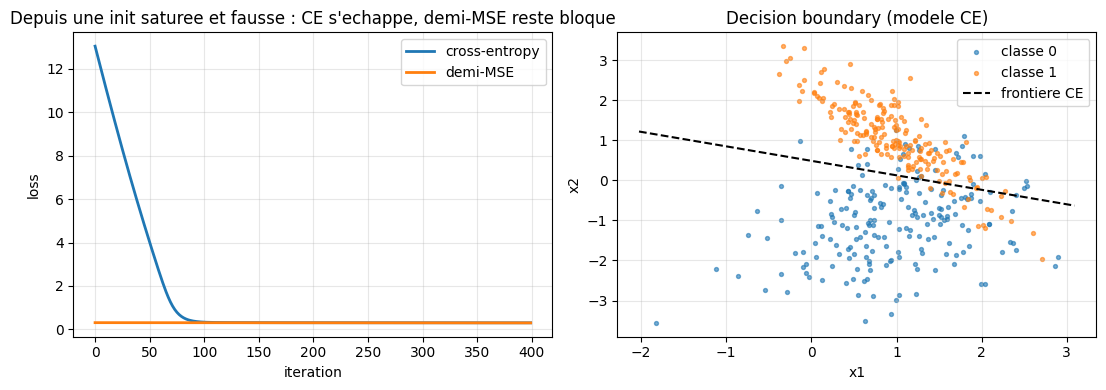

In [6]:
# L'experience decisive : partir SATURE et FAUX, et laisser la perte faire la difference.
import numpy as np, matplotlib.pyplot as plt

w0_sat = np.array([-8.0, -8.0, -8.0])        # init : sigmoide saturee dans le mauvais sens
w_ce, h_ce = entrainer(w0_sat, Xb, y, "ce", 0.2, 400)
w_mse, h_mse = entrainer(w0_sat, Xb, y, "mse", 0.2, 400)
print(f"init saturee et fausse : accuracy {acc(w0_sat, Xb, y):.3f}")
print(f"Cross-entropy : accuracy {acc(w_ce, Xb, y):.3f}  (s'echappe du piege du gradient)")
print(f"demi-MSE          : accuracy {acc(w_mse, Xb, y):.3f}  (reste bloque)")

# Pour un point sature et faux (p≈0, y=1), le gradient passe par p(1-p) : il meurt.
p_sat = 0.02
g_ce = p_sat - 1.0                      # proportionnel a (p - y), y=1
g_mse = (p_sat - 1.0) * p_sat * (1 - p_sat)
print(f"\nPoint sature p={p_sat:.2f}, y=1 : |gradient CE| = {abs(g_ce):.4f}  |  |gradient demi-MSE| = {abs(g_mse):.5f}")
print(f"  rapport CE/demi-MSE = {abs(g_ce) / abs(g_mse):.0f}x  -> le gradient demi-MSE est ~50x plus faible")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(h_ce, label="cross-entropy", lw=2)
axes[0].plot(h_mse, label="demi-MSE", lw=2)
axes[0].set_xlabel("iteration")
axes[0].set_ylabel("loss")
axes[0].set_title("Depuis une init saturee et fausse : CE s'echappe, demi-MSE reste bloque")
axes[0].legend()
axes[0].grid(alpha=0.3)
axes[1].scatter(X[y == 0, 0], X[y == 0, 1], s=8, alpha=0.6, label="classe 0")
axes[1].scatter(X[y == 1, 0], X[y == 1, 1], s=8, alpha=0.6, label="classe 1")
xx = np.linspace(X[:, 0].min() - 0.2, X[:, 0].max() + 0.2, 200)
yy = -(w_ce[0] * xx + w_ce[2]) / w_ce[1]      # frontiere du modele CE
axes[1].plot(xx, yy, "k--", lw=1.5, label="frontiere CE")
axes[1].set_xlabel("x1"); axes[1].set_ylabel("x2")
axes[1].set_title("Decision boundary (modele CE)")
axes[1].legend()
axes[1].grid(alpha=0.3)
plt.tight_layout()
plt.show()


**Lecture.** Depuis l'initialisation saturée, l'accuracy passe de 0,375 à 0,882 avec CE et à 0,393 avec demi-MSE après 400 pas à 0,2. Pour p=0,02 et y=1 le gradient CE vaut 0,9800 en valeur absolue contre 0,01921 pour la demi-MSE : le facteur p(1-p) explique ce rapport de 51. La MSE reste un objectif possible, notamment depuis une autre initialisation ; cette expérience ne démontre pas une interdiction générale.

***

## 4. KL comme distance entre modèles : un mini-modèle de langue et la température

La section 2 a mesuré $D_{KL}(p \| q)$ entre la vérité $p$ et un modèle $q$. Ici on inverse le regard : comparer entre elles deux **distributions de modèle** — c'est une notion utilisée par la régularisation de la série PostTraining, où l'on veut mesurer combien une policy s'éloigne d'une référence.

On construit un **mini-modèle de langue** from scratch : un **bigramme** de caractères entraîné sur le texte français (la probabilité du prochain caractère conditionnée au précédent). C'est un modèle réaliste — non trivial, mais assez petit pour tourner sur CPU. Deux usages :

1. **Qualité prédictive** : un bigramme peut prédire mieux qu'un unigramme (il capte la structure des suites), donc sa cross-entropy en bits/caractère est plus basse.
2. **Distance par température** : le **sampling par température** applique des logits ré-échelonnés $\mathrm{softmax}(z / T)$ ; une température $T < 1$ **concentre** la distribution, $T > 1$ l'**aplatit**. La KL entre la distribution de référence ($T = 1$) et sa version chauffée/refroidie mesure ce décalage.


In [7]:
# Mini-modele de langue bigramme : P(caractere | caractere precedent), lissage additif.
import numpy as np

def entrainer_bigramme(texte, alphabet):
    idx = {c: i for i, c in enumerate(alphabet)}
    A = len(alphabet)
    compt = np.full((A, A), 1.0)                 # lissage additif : aucun compteur nul
    prec = None
    for c in texte:
        i = idx[c]
        if prec is not None:
            compt[prec, i] += 1
        prec = i
    return compt / compt.sum(axis=1, keepdims=True)   # P[i, j] = P(j | i)

P_bigram = entrainer_bigramme(TEXTE, alphabet)

# Perte en bits/caractere de chaque modele sur le texte : unigramme (empirique) vs bigramme.
idx = {c: i for i, c in enumerate(alphabet)}
uni = p                                    # distribution unigramme (empirique, section 1)
bits_uni = 0.0; bits_uni_pair = 0.0; bits_bi = 0.0; n_bi = 0; prec = None
for c in TEXTE:
    i = idx[c]
    bits_uni += -np.log2(uni[i])
    if prec is not None:
        bits_uni_pair += -np.log2(uni[i])
        bits_bi += -np.log2(P_bigram[prec, i])
        n_bi += 1
    prec = i
print(f"perte unigramme : {bits_uni / len(TEXTE):.3f} bits/car.  |  bigramme : {bits_bi / n_bi:.3f} bits/car.")
print(f"gain du bigramme (il predit mieux la structure) : {bits_uni_pair / n_bi - bits_bi / n_bi:.3f} bits/car.")


perte unigramme : 4.533 bits/car.  |  bigramme : 4.009 bits/car.
gain du bigramme (il predit mieux la structure) : 0.522 bits/car.


La distribution conditionnelle du contexte espace permet maintenant de mesurer la KL selon la température.

caractere contexte = ' '  (le plus frequent) — distribution : [0.003 0.003 0.014 0.003 0.003 0.003]...
  T = 0.3   KL(ref || ref@T) = 1.7047 bits   H(dist) = 3.2406
  T = 1.0   KL(ref || ref@T) = -0.0000 bits   H(dist) = 5.2835
  T = 2.0   KL(ref || ref@T) = 0.1424 bits   H(dist) = 5.7206

minimum de KL sur le balayage en T = 1.00  (attendu : 1.0, temperature neutre)


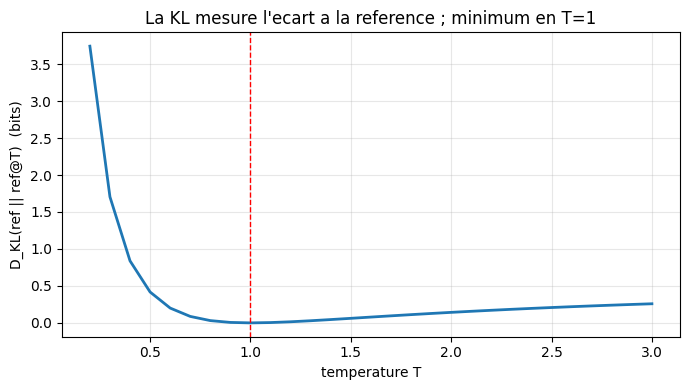

Températures invalides et référence uniforme : OK
Température subnormale : OK
Logits et température extrêmes : OK


In [8]:
# Distance par temperature : KL(ref || ref@T), minimisee en T=1.
import numpy as np

def softmax_temperature(logits, T):
    if not np.isfinite(T) or T <= 0:
        raise ValueError("température finie strictement positive requise")
    logits = np.asarray(logits, dtype=float)
    if logits.ndim != 1 or not len(logits) or not np.all(np.isfinite(logits)):
        raise ValueError("logits finis non vides requis")
    with np.errstate(over="ignore"):
        if T >= 1:
            logits = logits / T
            logits = logits - logits.max()
        else:
            logits = (logits - logits.max()) / T
    e = np.exp(logits)
    return e / e.sum()

# Contexte le plus frequent (la distribution de reference : ce qui suit ce caractere).
ctx = alphabet[int(np.argmax(p))]
ref = P_bigram[idx[ctx]]                     # distribution de reference (contexte donne)
log_ref = np.log(ref)

print(f"caractere contexte = {ctx!r}  (le plus frequent) — distribution : {np.round(ref[:6], 3)}...")
for T in [0.3, 1.0, 2.0]:
    dist = softmax_temperature(log_ref, T)
    print(f"  T = {T:<4}  KL(ref || ref@T) = {kl(ref, dist):.4f} bits   H(dist) = {entropie_p(dist):.4f}")

# Balayage complet : la KL(ref||ref@T) a bien son minimum en T=1.
Tvals = np.linspace(0.2, 3.0, 29)
Kvals = [kl(ref, softmax_temperature(log_ref, T)) for T in Tvals]
Tmin = Tvals[int(np.argmin(Kvals))]
print(f"\nminimum de KL sur le balayage en T = {Tmin:.2f}  (attendu : 1.0, temperature neutre)")

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(Tvals, Kvals, lw=2)
ax.axvline(1.0, color="red", ls="--", lw=1)
ax.set_xlabel("temperature T")
ax.set_ylabel("D_KL(ref || ref@T)  (bits)")
ax.set_title("La KL mesure l'ecart a la reference ; minimum en T=1")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Un uniforme garde KL=0 à toute température ; refuser les entrées invalides.
for t in (.3, 1., 2.):
    assert abs(kl([.5, .5], softmax_temperature(np.log([.5, .5]), t))) < 1e-12
for t in (0, -1, np.nan, np.inf):
    try: softmax_temperature(np.log([.5, .5]), t)
    except ValueError: pass
    else: raise AssertionError("température invalide acceptée")
print("Températures invalides et référence uniforme : OK")

assert np.array_equal(softmax_temperature(np.log([.9, .1]), 1e-320), [1., 0.])
print("Température subnormale : OK")

assert np.allclose(softmax_temperature([-1e308, 1e308], 1e308), [0.11920292202211755, 0.8807970779778823])
print("Logits et température extrêmes : OK")


**Lecture.** Sur le même texte utilisé pour entraîner le bigramme, la perte vaut 4,009 bits par transition ; le gain apparié face à l'unigramme sur ces mêmes 1 306 positions vaut 0,522 bit. Ce résultat en entraînement ne mesure pas la généralisation. Pour le contexte espace, H vaut 3,2406, 5,2835 et 5,7206 bits à T=0,3, 1 et 2 ; KL(ref || ref@T) vaut 1,7047, 0 et 0,1424 bit. T=1 est un minimum, sans être nécessairement unique : une référence uniforme est inchangée à toute température.

## Exercice 3 — Température et KL

Calculez KL(ref || ref@T) en bits pour une référence strictement positive et normalisée et une température finie T>0. Tracez la courbe sur les 29 températures de 0,2 à 3 et vérifiez que T=1 est un minimum, sans imposer son unicité. Refusez vecteurs vides, non finis, non positifs ou de masse différente de 1 et températures invalides.

In [9]:
# Exercice 3 : KL(ref || ref@T), pour une température strictement positive.
def kl_T(ref, T):
    # TODO étudiant : calculer la distribution tempérée puis la KL en bits.
    return None

def verifier_temperature(f):
    import math
    for rr, t in [([.2,.8],1), ([.2,.8],2), ([.5,.5],.3), ([.7,.2,.1],.4)]:
        poids = [x**(1/t) for x in rr]
        qq = [x/sum(poids) for x in poids]
        attendu = sum(x*math.log2(x/y) for x,y in zip(rr,qq))
        valeur = f(rr,t)
        if valeur is None: return False
        if not math.isfinite(valeur) or not math.isclose(valeur, attendu, abs_tol=1e-10):
            raise AssertionError("KL de température incorrecte")
    for rr, t in [([.5,.5],0), ([.5,.5],float("nan")), ([],1), ([float("inf"),1],1), ([.5,.5],-1), ([.5,.5],float("inf")), ([-.1,1.1],1), ([.2,.2],1)]:
        try: f(rr,t)
        except ValueError: pass
        else: raise AssertionError("entrée invalide acceptée")
    return True
print("Exercice 3 :", "validé" if verifier_temperature(kl_T) else "à compléter")

Exercice 3 : à compléter


***

## 5. Les ponts : les mêmes quantités dans DPO et GRPO

Les deux grandeurs manipulées ici — la **cross-entropy** et la **divergence de KL** — sont les briques des losses de toute la série. Deux exemples précis, dans [PT_03](../../../GenAI/PostTraining/PT_03_dpo_direct_preference.ipynb) (DPO) et [PT_04](../../../GenAI/PostTraining/PT_04_grpo_deepseek_r1.ipynb) :

- **DPO (PT_03)** : la récompense implicite est $\beta \cdot \log \frac{\pi_\theta}{\pi_{ref}}$, et la loss est un `-log sigmoid` du **différentiel de log-rapports** entre la réponse choisie et la réponse rejetée. C'est un **log-ratio de probabilités** ($\log \pi_\theta - \log \pi_{ref}$) — la même différence de log-probas que notre $\log_2 \frac{p}{q}$, à la base près. Le paramètre $\beta = 0.1$ (PT_03) est le **coefficient de régularisation KL**.
- **GRPO/PPO (PT_04)** : la loss est un `clipped surrogate` $\min(r_i \hat{A}_i, \mathrm{clip}(r_i, 1-\varepsilon, 1+\varepsilon) \hat{A}_i)$ **plus un penalty KL** $\beta \cdot D_{KL}(\pi_\theta \| \pi_{ref})$. Le `ratio` $r_i = \pi_\theta / \pi_{old}$ est un rapport de probabilités, et le penalty KL est **exactement** notre $D_{KL}$ de la section 2. Le $\beta = 0.04$ (PT_04, défaut DeepSeek) règle la force de ce rappel vers la référence.

Un coefficient de rappel faible peut permettre à la politique de s'éloigner de sa référence, sans impliquer à lui seul une panne numérique ou un logarithme de zéro. En entraînement, cette KL théorique est souvent estimée sur des échantillons ; le calcul suivant en donne la somme exacte sur quatre tokens, sans reproduire un entraînement GRPO réel.


In [10]:
# Les memes primitives dans le loss DPO et le penalty KL de GRPO.
import numpy as np

def softmax(z):
    e = np.exp(z - np.max(z))
    return e / e.sum()

def sigmoid(z):
    return 1.0 / (1.0 + np.exp(-z))

# Deux logits (policy vs reference) sur 4 "tokens" d'un vocabulaire-jouet.
logits_policy = np.array([3.0, 1.5, 4.0, 0.5])
logits_ref    = np.array([2.8, 2.6, 3.2, 1.8])
pi = softmax(logits_policy)
pi_ref = softmax(logits_ref)

log_ratio = np.log(pi) - np.log(pi_ref)          # log(pi_theta) - log(pi_ref)
print("log-ratio (pi_theta / pi_ref) :", np.round(log_ratio, 3))
print("recompense implicite DPO  (beta=0.1 * log-ratio) :", np.round(0.1 * log_ratio, 3))

# Loss DPO = -log sigmoid(beta * (log-ratio_choisi - log-ratio_rejete))
lr_c = log_ratio[2]    # "choisi"  (le token ou la policy est la plus confiante)
lr_r = log_ratio[1]    # "rejete"
loss_dpo = np.logaddexp(0, -0.1 * (lr_c - lr_r))
print(f"loss DPO = -log sigmoid(beta*(log-ratio_choisi - log-ratio_rejete)) = {loss_dpo:.4f}")

# Penalty KL de GRPO : D_KL(pi_theta || pi_ref) = sum pi_theta * log-ratio  (exactement la section 2)
kl_grpo = kl(pi, pi_ref)
print(f"KL(pi_theta || pi_ref) = {kl_grpo:.4f} bits = {np.sum(pi * log_ratio):.4f} nats (bits × ln 2)")


log-ratio (pi_theta / pi_ref) : [-0.09 -1.39  0.51 -1.59]
recompense implicite DPO  (beta=0.1 * log-ratio) : [-0.009 -0.139  0.051 -0.159]
loss DPO = -log sigmoid(beta*(log-ratio_choisi - log-ratio_rejete)) = 0.6027
KL(pi_theta || pi_ref) = 0.3073 bits = 0.2130 nats (bits × ln 2)


**Lecture.** Le différentiel de log-rapports naturels donne une perte DPO jouet de 0,6027. La KL exacte sur quatre tokens vaut 0,2130 nat, soit 0,3073 bit : la conversion multiplie les bits par ln(2). Le calcul illustre les grandeurs utilisées par les méthodes de préférence sans reproduire leur entraînement sur des séquences.

## Contre-sens usuels et récapitulatif des exercices

La CE est égale à l'entropie plus la KL ; celle-ci est non négative et asymétrique. Un zéro sur le support de p donne une CE infinie, sauf si l'on change la distribution par un lissage normalisé. La demi-MSE peut apprendre, mais son gradient peut être faible en saturation. Le gain du bigramme est ici mesuré sur l'entraînement. Une température neutre donne KL=0, éventuellement avec d'autres minima pour une référence uniforme.

Exercices : [calculer l’entropie du second texte](#Exercice-1--Entropie-du-second-texte), [lisser une distribution et calculer sa CE](#Exercice-2--Lissage-normalisé), puis [étudier KL en fonction de la température](#Exercice-3--Température-et-KL). Les trois stubs ci-dessus restent à compléter.

Voir aussi le [glossaire](GLOSSAIRE.md).

## À retenir

L'entropie mesure une surprise moyenne ; la CE ajoute le surcoût KL d'un modèle. Le cas saturé illustre une différence de gradients, et le modèle de caractères illustre une comparaison sur l'entraînement.

## Vérifiez votre compréhension

Pourquoi une KL n'est-elle pas une distance ?

<details><summary>Réponse</summary>Elle est asymétrique.</details>

Pourquoi T=1 peut-il ne pas être le seul minimum ?

<details><summary>Réponse</summary>Une distribution uniforme reste uniforme pour toute température positive.</details>

## Pour aller plus loin

Les ouvrages suivants développent les fondements probabilistes et les liens avec l’apprentissage.

## Références

1. Shannon, C. E. (1948). *A Mathematical Theory of Communication*. Bell System Technical Journal, 27, 379–423.
2. Kullback, S. & Leibler, R. A. (1951). *On Information and Sufficiency*. Annals of Mathematical Statistics, 22(1), 79–86.
3. Goodfellow, I., Bengio, Y. & Courville, A. (2016). *Deep Learning*, section 3.13, p. 71. MIT Press. https://www.deeplearningbook.org/contents/TOC.html
